# RSGM vs the HuProSO3 flow on AMASS

Unconditional pose priors on SO(3)^19, evaluated the same way: RSGM (Riemannian score-based generative model, `hp/models/rsgm.py`, trained with `train_rsgm.ipynb`) and the HuProSO3 normalizing flow (trained with the old `SO3PriorTrainer`).

The models can be trained on differently compressed data (every N-th frame, or all frames). `MODELS` lists them; for each the notebook finds out what it was trained on (the rotation folder, the number of training frames, iterations, batch, epochs, time). `PAIRS` says which models are compared head to head. A model that does not exist yet (e.g. still training) is skipped.

What a pair means:
- **same data** (e.g. RSGM c30 vs flow c30): a clean comparison of the two models;
- **RSGM full vs the authors' prior `id_0900`:** both on all frames, but the authors trained on their AMASS release (most likely SMPL-X **N**), ours is SMPL-X **G** (see `evaluate_priors.ipynb`), so the difference mixes the model and the release;
- **RSGM c30 vs RSGM full** (same model, other data): what the compression costs.

Every model is evaluated with the harness of the model zoo (`hp.evaluation.evaluate`) on the **full** official test split (Transitions + SSM, all frames), whatever it was trained on:
- **log-likelihood:** all are densities relative to the uniform distribution on SO(3)^19, so the numbers compare. RSGM's comes from the probability flow ODE with `RSGM_LIKELIHOOD_STEPS` midpoint steps: with 100 steps it is ~0.3 nats too high, with 200 ~0.06, with 400 converged (measured on rsgm_c30);
- **Wasserstein, recall, precision** of generated poses (degrees per joint), next to the **contrast**: real poses of other subjects (a train split, `CONTRAST_ROTATIONS`, the same for every model) in place of a generator;
- a **paired log-likelihood** comparison on the same test poses for every pair, which is more precise than the difference of two means.

Flows trained with `SO3PriorTrainer` are converted into the format of the model zoo once (weights and `permute_dims` unchanged). Reports go to `REPORT_DIR/<model>.json` and are reused while the evaluation settings are the same; `RECOMPUTE = True` evaluates again.

In [1]:
import json
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from omegaconf import OmegaConf

from hp.data.amass_cfg import ORIGINAL_AMASS_SPLITS, AmassJoints4Learning
from hp.evaluation.cli import format_report
from hp.evaluation.data import load_reference
from hp.evaluation.evaluate import EvalConfig, evaluate, load_report, save_report
from hp.models import build_model
from hp.models.io import MANIFEST, load_model, save_model
from hp.models.so3_flow import PAPER_FLOW_CONFIG
from hp.utils.paths import REPO_ROOT
from tqdm.auto import tqdm

# ---- parameters ----------------------------------------------------------------------
# A model is either a run of the model zoo ("run": a run folder, or a folder of runs: the newest finished one is
# taken) or a flow of SO3PriorTrainer ("legacy": its folder, "zoo": where its converted copy goes, "data": the
# rotation folder it was trained on, or None if that is not our data).
MODELS = {
    "RSGM c30":     dict(run="~/data/experiments/rsgm_c30", weights="weights_ema"),
    "RSGM full":    dict(run="~/data/experiments/rsgm", weights="weights_ema"),
    "flow c30":     dict(legacy="~/data/experiments/prior_c30/id_9030", zoo="~/data/experiments/so3_flow_c30/id_9030",
                         data="~/data/AMASS_rotations_c30"),
    "flow authors": dict(legacy=str(REPO_ROOT / "experiments" / "pretrained_models" / "id_0900"),
                         zoo="~/data/experiments/so3_flow_authors/id_0900", data=None),
}
PAIRS = [("RSGM c30", "flow c30"), ("RSGM full", "flow authors"), ("RSGM full", "RSGM c30")]
FULL_ROTATIONS = "~/data/AMASS_rotations"              # all frames: the test runs on these
CONTRAST_ROTATIONS = "~/data/AMASS_rotations_c30"      # the contrast: a train split (every 30th frame is enough)
SPLIT = "original"                                     # the official AMASS split
DEVICES = {"rsgm": "mps", "so3_flow": "cpu"}           # by model type; RSGM samples 3-5x faster on mps
RSGM_LIKELIHOOD_STEPS = 200                            # ODE steps of RSGM's log-likelihood (the config has 100)
EVAL = dict(n_wasserstein=2000, n_queries=2000, n_generated=20_000, n_likelihood=5000, repeats=3, seed=0,
            sample_batch=2000, chunk=20_000)           # the fields of hp.evaluation.EvalConfig
N_PAIRED = 2000                                        # test poses of the paired log-likelihood comparison
REPORT_DIR = "~/data/experiments/rsgm_vs_flow"         # reports and the summary go here
RECOMPUTE = False                                      # True: evaluate again even if a report fits
# ----------------------------------------------------------------------------------------

expand = lambda p: Path(p).expanduser()
REPORT_DIR = expand(REPORT_DIR)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

## 1. The models and what they were trained on

Runs of the model zoo: the newest finished run of a folder (one with `history.json`). Flows of `SO3PriorTrainer`: converted into the model zoo (`SO3Flow` with the settings of the paper, which must be the ones the flow was trained with). The training data: the rotation folder (`..._c<N>`: every N-th frame, no suffix: all frames) and its number of training frames.

In [2]:
def stride_of(rotations):
    # Every N-th frame from the name of a rotation folder: AMASS_rotations_c30 -> 30, AMASS_rotations -> 1.
    match = re.search(r"_c([0-9.]+)$", str(rotations).rstrip("/"))
    return float(match.group(1)) if match else 1


def train_frames(rotations):
    # Frames of the official train split in a rotation folder (memory-mapped: only the shapes are read).
    return sum(torch.load(expand(rotations) / f"{d}.pt", mmap=True).shape[0] for d in ORIGINAL_AMASS_SPLITS["train"])


def newest_run(path):
    path = expand(path)
    if (path / MANIFEST).is_file():
        return path
    runs = sorted(p for p in path.glob("run_[0-9][0-9][0-9][0-9]") if (p / "history.json").is_file() and (p / MANIFEST).is_file())
    return runs[-1] if runs else None


info = {}  # model -> run folder, weights, training data and budget
for name, m in MODELS.items():
    if "run" in m:
        run = newest_run(m["run"])
        if run is None:
            print(f"{name}: skipped, no finished run in {m['run']}")
            continue
        c = OmegaConf.load(run / "config.yaml")
        rotations = c.data.rotations
        seconds_file = run / "train_time.json"
        info[name] = dict(run=run, weights=m["weights"], rotations=rotations, iterations=c.train.max_iterations,
                          batch=c.train.batch_size, seconds=json.loads(seconds_file.read_text())["seconds"] if seconds_file.is_file() else None)
    else:
        legacy, zoo = expand(m["legacy"]), expand(m["zoo"])
        if not legacy.is_dir():
            print(f"{name}: skipped, {legacy} not found")
            continue
        c = OmegaConf.load(legacy / "config.yaml")
        mismatch = {k: (v, c.so3.get(k)) for k, v in PAPER_FLOW_CONFIG.items() if c.so3.get(k) != v}
        assert not mismatch, f"{name} was trained with other flow settings (paper, legacy): {mismatch}"
        if not (zoo / MANIFEST).is_file():
            flow = build_model("so3_flow", num_joints=len(AmassJoints4Learning))
            flow.load_legacy_checkpoint(legacy)
            save_model(flow, zoo)
            print(f"{name}: converted {legacy} -> {zoo}")
        info[name] = dict(run=zoo, weights="weights", rotations=m["data"], iterations=c.max_iterations,
                          batch=c.batch_size, seconds=None)
    i = info[name]
    i["type"] = json.loads((i["run"] / MANIFEST).read_text())["build_args"]["name"]
    if i["rotations"] is None:
        i["data"], i["frames"] = "authors' AMASS (all frames)", None
    else:
        n = stride_of(i["rotations"])
        i["data"] = "all frames" if n == 1 else f"every {n:g}-th frame"
        i["frames"] = train_frames(i["rotations"])

print(f"{'model':14s} {'type':9s} {'trained on':28s} {'train frames':>13s} {'iterations':>11s} {'batch':>6s} {'epochs':>7s} {'time':>9s}")
for name, i in info.items():
    frames = f"{i['frames']:,}" if i["frames"] else "-"
    epochs = f"{i['iterations'] * i['batch'] / i['frames']:.1f}" if i["frames"] else "-"
    minutes = f"{i['seconds'] / 60:.0f} min" if i["seconds"] else "-"
    print(f"{name:14s} {i['type']:9s} {i['data']:28s} {frames:>13s} {i['iterations']:11,} {i['batch']:6,} {epochs:>7s} {minutes:>9s}")
print("(epochs and frames of the authors' prior: their data is not ours; time: only for runs that stored it)")

flow authors: converted /Users/evgeniifedorov/Documents/HuProSO/experiments/pretrained_models/id_0900 -> /Users/evgeniifedorov/data/experiments/so3_flow_authors/id_0900
model          type      trained on                    train frames  iterations  batch  epochs      time
RSGM c30       rsgm      every 30-th frame                  497,707     100,000    512   102.9    17 min
RSGM full      rsgm      all frames                      14,779,964     100,000    512     3.5    22 min
flow c30       so3_flow  every 30-th frame                  497,707       2,000  2,000     8.0         -
flow authors   so3_flow  authors' AMASS (all frames)              -      20,000  2,000       -         -
(epochs and frames of the authors' prior: their data is not ours; time: only for runs that stored it)


## 2. The real poses

The full test split (all frames), and the contrast (a train split, the same for every model).

In [3]:
reference = load_reference("test", FULL_ROTATIONS, SPLIT)
contrast = load_reference("train", CONTRAST_ROTATIONS, SPLIT)
print(f"test: {len(reference):,} poses (all frames of {FULL_ROTATIONS}), contrast: {len(contrast):,} poses (train of {CONTRAST_ROTATIONS})")

test: 117,679 poses (all frames of ~/data/AMASS_rotations), contrast: 497,707 poses (train of ~/data/AMASS_rotations_c30)


## 3. Evaluate

The same `EvalConfig` for every model. A saved report is reused if it was made with the same settings (evaluation, test and contrast data, RSGM's likelihood steps) for the same run and weights.

In [4]:
def load(name):
    i = info[name]
    model = load_model(i["run"], device=DEVICES[i["type"]], weights=i["weights"])
    if i["type"] == "rsgm":
        model.likelihood_steps = RSGM_LIKELIHOOD_STEPS
    return model


def settings(name):
    i = info[name]
    return dict(eval=EVAL, test=str(FULL_ROTATIONS), contrast=str(CONTRAST_ROTATIONS), split=SPLIT, run=str(i["run"]),
                weights=i["weights"], likelihood_steps=RSGM_LIKELIHOOD_STEPS if i["type"] == "rsgm" else None)


reports = {}
for name in info:
    path = REPORT_DIR / f"{name.replace(' ', '_')}.json"
    if path.is_file() and not RECOMPUTE and load_report(path).get("settings") == settings(name):
        reports[name] = load_report(path)
        print(f"--- {name}: saved report {path}")
    else:
        start = time.perf_counter()
        model = load(name)
        report = evaluate(model, reference, EvalConfig(**EVAL), contrast, progress=True)
        report["settings"] = settings(name)
        save_report(report, path)
        reports[name] = report
        print(f"--- {name}: evaluated in {(time.perf_counter() - start) / 60:.1f} min on {model.device}, saved to {path}")
    print(format_report(reports[name]))

sampling:   0%|          | 0/10 [00:00<?, ?batch/s]

wasserstein:   0%|          | 0/180 [00:00<?, ?OT/s]

nearest neighbours:   0%|          | 0/3 [00:00<?, ?repeat/s]

log-likelihood:   0%|          | 0/15000 [00:00<?, ?pose/s]

--- RSGM c30: evaluated in 6.6 min on mps:0, saved to /Users/evgeniifedorov/data/experiments/rsgm_vs_flow/RSGM_c30.json
rsgm: 1,168,441 parameters, 0.08 s per 1000 samples
real poses: 117,679
wasserstein (deg per joint): generated 17.58 +- 0.10, same-set floor 6.37 +- 0.08
recall    (deg per joint): mean 11.71 +- 0.03, p95 19.30, within 5 deg 0.00
precision (deg per joint): mean 13.48 +- 0.09, p95 20.80, within 5 deg 0.00
same-set  (deg per joint): mean 1.64 +- 0.02, p95 5.12, within 5 deg 0.95
contrast  (deg per joint): wasserstein 17.49 +- 0.05, recall 11.75 +- 0.02, precision 13.49 +- 0.03
  contrast = real poses of other subjects: what exactly reproducing the training poses would score. Compare the model with it; the same-set numbers are no goal (neighbouring frames are nearly identical).
log-likelihood: 136.97 +- 0.11 on SO(3)^J


...

sampling:   0%|          | 0/10 [00:00<?, ?batch/s]

wasserstein:   0%|          | 0/180 [00:00<?, ?OT/s]

nearest neighbours:   0%|          | 0/3 [00:00<?, ?repeat/s]

log-likelihood:   0%|          | 0/15000 [00:00<?, ?pose/s]

--- flow authors: evaluated in 2.0 min on cpu, saved to /Users/evgeniifedorov/data/experiments/rsgm_vs_flow/flow_authors.json
so3_flow: 1,293,104 parameters, 2.07 s per 1000 samples
real poses: 117,679
wasserstein (deg per joint): generated 19.01 +- 0.02, same-set floor 6.37 +- 0.08
recall    (deg per joint): mean 12.00 +- 0.04, p95 19.71, within 5 deg 0.00
precision (deg per joint): mean 14.97 +- 0.11, p95 24.92, within 5 deg 0.00
same-set  (deg per joint): mean 1.64 +- 0.02, p95 5.12, within 5 deg 0.95
contrast  (deg per joint): wasserstein 17.49 +- 0.05, recall 11.75 +- 0.02, precision 13.49 +- 0.03
  contrast = real poses of other subjects: what exactly reproducing the training poses would score. Compare the model with it; the same-set numbers are no goal (neighbouring frames are nearly identical).
log-likelihood: 132.96 +- 0.19 on SO(3)^J


## 4. Summary

Higher log-likelihood is better; lower Wasserstein, recall and precision distances are better. The contrast row is the yardstick: real poses of other subjects.

In [5]:
pm = lambda x: f"{x['mean']:6.2f} +- {x['std']:4.2f}"
print(f"full test split ({len(reference):,} poses); angles in degrees per joint\n")
print(f"{'':14s} {'trained on':28s} {'log-likelihood':>16s} {'Wasserstein':>16s} {'recall':>16s} {'precision':>16s} {'s/1000 samples':>15s}")
for name, r in reports.items():
    print(f"{name:14s} {info[name]['data']:28s} {pm(r['likelihood']):>16s} {pm(r['wasserstein']['generated']['joint_mean_deg']):>16s} "
          f"{pm(r['recall']['mean_deg']):>16s} {pm(r['precision']['mean_deg']):>16s} {r['sampling']['seconds_per_1000']:15.2f}")
r = next(iter(reports.values()))
print(f"{'contrast':14s} {'(real poses, other subjects)':28s} {'-':>16s} {pm(r['wasserstein']['contrast']['joint_mean_deg']):>16s} "
      f"{pm(r['contrast_recall']['mean_deg']):>16s} {pm(r['contrast_precision']['mean_deg']):>16s}")
print(f"\nNaN share of the log-likelihoods: " + ", ".join(f"{n} {r['likelihood']['nan_fraction']:.4f}" for n, r in reports.items()))

full test split (117,679 poses); angles in degrees per joint

               trained on                     log-likelihood      Wasserstein           recall        precision  s/1000 samples
RSGM c30       every 30-th frame              136.97 +- 0.11    17.58 +- 0.10    11.71 +- 0.03    13.48 +- 0.09            0.08
RSGM full      all frames                     137.15 +- 0.11    17.59 +- 0.09    11.72 +- 0.04    13.53 +- 0.11            0.08
flow c30       every 30-th frame              135.18 +- 0.18    17.89 +- 0.08    11.55 +- 0.05    13.86 +- 0.07            2.19
flow authors   authors' AMASS (all frames)    132.96 +- 0.19    19.01 +- 0.02    12.00 +- 0.04    14.97 +- 0.11            2.07
contrast       (real poses, other subjects)                -    17.49 +- 0.05    11.75 +- 0.02    13.49 +- 0.03

NaN share of the log-likelihoods: RSGM c30 0.0000, RSGM full 0.0000, flow c30 0.0000, flow authors 0.0000


## 5. Wasserstein per joint

Optimal transport between generated and real test poses for every joint alone, next to the contrast.

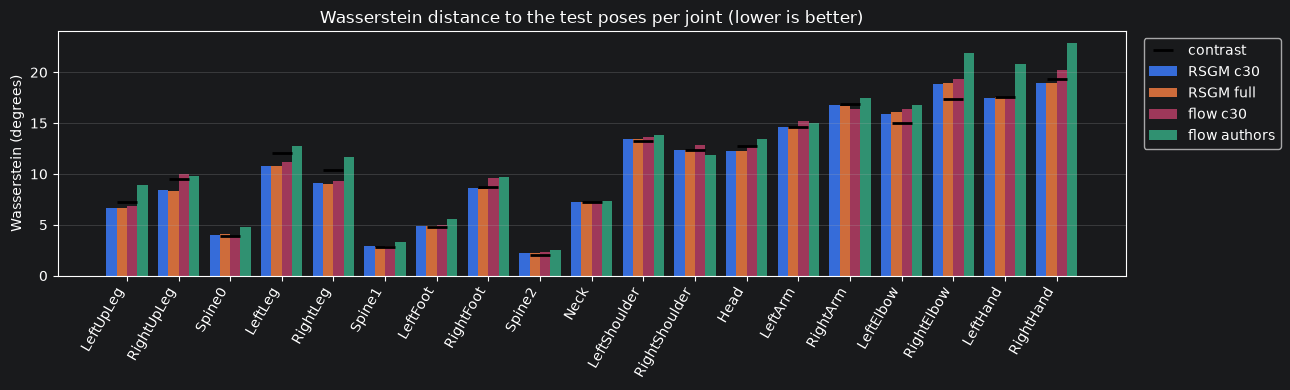

In [6]:
joints = [j.name for j in AmassJoints4Learning]
x, width = np.arange(len(joints)), 0.8 / len(reports)
fig, ax = plt.subplots(figsize=(13, 4))
for k, (name, r) in enumerate(reports.items()):
    ax.bar(x + (k - (len(reports) - 1) / 2) * width, r["wasserstein"]["generated"]["by_joint_deg"], width=width, color=f"C{k}", label=name)
ax.plot(x, next(iter(reports.values()))["wasserstein"]["contrast"]["by_joint_deg"], "k_", ms=14, mew=2, label="contrast")
ax.set_xticks(x, joints, rotation=60, ha="right")
ax.set_ylabel("Wasserstein (degrees)")
ax.set_title("Wasserstein distance to the test poses per joint (lower is better)")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

## 6. Paired log-likelihood

Every model on the same `N_PAIRED` random test poses, then the difference per pose for every pair. The difference has a much smaller spread than the log-likelihoods themselves (a pose that is unusual is unusual for both), so its mean is the precise answer to "which model gives the test poses more density".

log-likelihood RSGM c30:   0%|          | 0/8 [00:00<?, ?batch/s]

log-likelihood RSGM full:   0%|          | 0/8 [00:00<?, ?batch/s]

log-likelihood flow authors:   0%|          | 0/8 [00:00<?, ?batch/s]

log-likelihood flow c30:   0%|          | 0/8 [00:00<?, ?batch/s]

RSGM c30 - flow c30: +1.91 +- 0.12 (s.e.m.), median +1.76; RSGM c30 higher on 62% of 2,000 poses
RSGM full - flow authors: +4.11 +- 0.13 (s.e.m.), median +4.13; RSGM full higher on 76% of 2,000 poses
RSGM full - RSGM c30: +0.18 +- 0.05 (s.e.m.), median +0.28; RSGM full higher on 55% of 2,000 poses


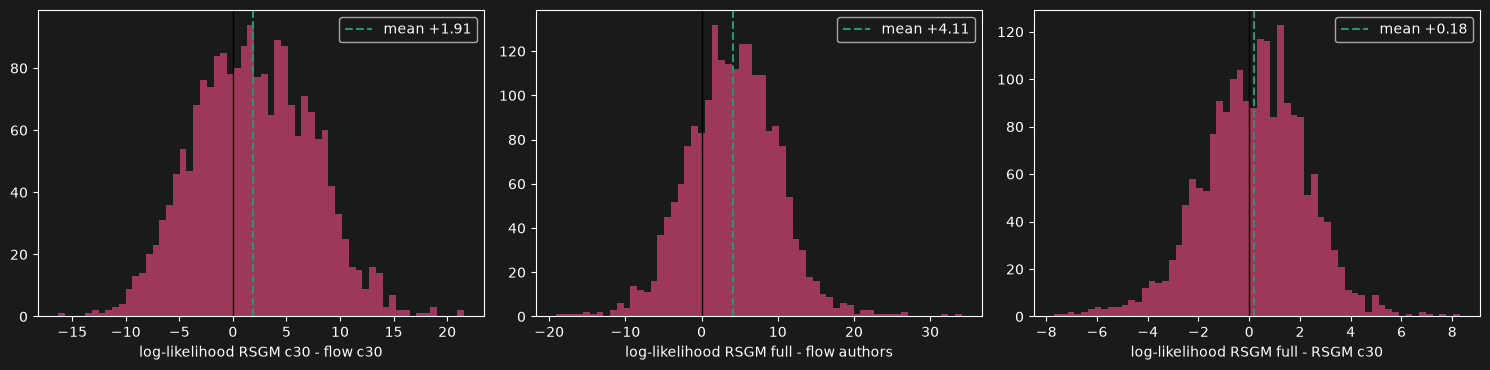

saved to /Users/evgeniifedorov/data/experiments/rsgm_vs_flow/summary.json


In [7]:
rng = np.random.default_rng(EVAL["seed"] + 1)
poses = reference[rng.choice(len(reference), min(N_PAIRED, len(reference)), replace=False)]
needed = sorted({n for pair in PAIRS for n in pair if n in info})
ll = {}
for name in needed:
    model = load(name)
    with torch.no_grad():
        ll[name] = torch.cat([model.log_prob(poses[i:i + 250].to(model.device)).float().cpu()
                              for i in tqdm(range(0, len(poses), 250), desc=f"log-likelihood {name}", unit="batch")]).numpy()

pairs = [(a, b) for a, b in PAIRS if a in ll and b in ll]
for a, b in PAIRS:
    if (a, b) not in pairs:
        print(f"{a} vs {b}: skipped, {' and '.join(n for n in (a, b) if n not in ll)} not available")
paired = {}
fig, axes = plt.subplots(1, max(1, len(pairs)), figsize=(5 * max(1, len(pairs)), 3.8), squeeze=False)
for ax, (a, b) in zip(axes[0], pairs):
    diff = ll[a] - ll[b]
    d = diff[np.isfinite(diff)]
    sem = d.std(ddof=1) / np.sqrt(len(d))
    paired[f"{a} - {b}"] = dict(n=int(len(d)), mean=float(d.mean()), sem=float(sem), median=float(np.median(d)), a_higher=float((d > 0).mean()))
    print(f"{a} - {b}: {d.mean():+.2f} +- {sem:.2f} (s.e.m.), median {np.median(d):+.2f}; {a} higher on {(d > 0).mean():.0%} "
          f"of {len(d):,} poses")
    ax.hist(d, bins=60, color="C2")
    ax.axvline(0, color="k", lw=1)
    ax.axvline(d.mean(), color="C3", ls="--", label=f"mean {d.mean():+.2f}")
    ax.set_xlabel(f"log-likelihood {a} - {b}")
    ax.legend()
fig.tight_layout()
plt.show()

summary = {"settings": dict(eval=EVAL, test=str(FULL_ROTATIONS), contrast=str(CONTRAST_ROTATIONS), split=SPLIT,
                            rsgm_likelihood_steps=RSGM_LIKELIHOOD_STEPS, n_paired=len(poses)),
           "models": {n: {**{k: str(v) if isinstance(v, Path) else v for k, v in info[n].items()},
                          "likelihood": reports[n]["likelihood"]} for n in reports},
           "paired_log_likelihood": paired}
(REPORT_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
print(f"saved to {REPORT_DIR / 'summary.json'}")